# Example 14: Knot supervised

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from xkan import KANNetwork, fit
from xkan.interp import feature_score
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

seed = 42
torch.manual_seed(seed)
np.random.seed(seed)

# Download data: https://colab.research.google.com/github/deepmind/mathematics_conjectures/blob/main/knot_theory.ipynb#scrollTo=l10N2ZbHu6Ob
# (that notebook's gs://maths_conjectures/knot_theory/knot_theory_invariants.csv, saved here as knot_data.csv)
df = pd.read_csv("./knot_data.csv")
df.keys()

X = df[df.keys()[1:-1]].to_numpy()
Y = df[['signature']].to_numpy()

# normalize X
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X = (X - X_mean[np.newaxis,:])/X_std[np.newaxis,:]
input_normalier = [X_mean, X_std]

# normalize Y
max_signature = np.max(Y)
min_signature = np.min(Y)
Y = ((Y-min_signature)/2).astype(int)
n_class = int((max_signature-min_signature)/2+1)
output_normalier = [min_signature, 2]

num = X.shape[0]
n_feature = X.shape[1]
train_ratio = 0.8
train_id_ = np.random.choice(num, int(num*train_ratio), replace=False)
test_id_ = np.array(list(set(range(num))-set(train_id_)))

# inputs under 'x', the class labels (integers) under 'y'
dtype = torch.get_default_dtype()
train = {'x': torch.from_numpy(X[train_id_]).type(dtype).to(device),
         'y': torch.from_numpy(Y[train_id_][:,0]).type(torch.long).to(device)}
test = {'x': torch.from_numpy(X[test_id_]).type(dtype).to(device),
        'y': torch.from_numpy(Y[test_id_][:,0]).type(torch.long).to(device)}

cuda


In [2]:
def train_acc():
    return torch.mean((torch.argmax(model(train['x']), dim=1) == train['y']).float())

def test_acc():
    return torch.mean((torch.argmax(model(test['x']), dim=1) == test['y']).float())

model = KANNetwork([n_feature, 1, n_class], grid=5, k=3, seed=seed, device=device)
history = fit(model, train, test, lamb=0.005, batch=1024, loss=nn.CrossEntropyLoss())
print('train_loss', history['train/y'][-1], '| reg', history['train/reg/kan'][-1],
      '| train_acc', train_acc().item(), '| test_acc', test_acc().item())

train_loss 0.657120406627655 | reg 0.13236288726329803 | train_acc 0.739317774772644 | test_acc 0.7417640686035156


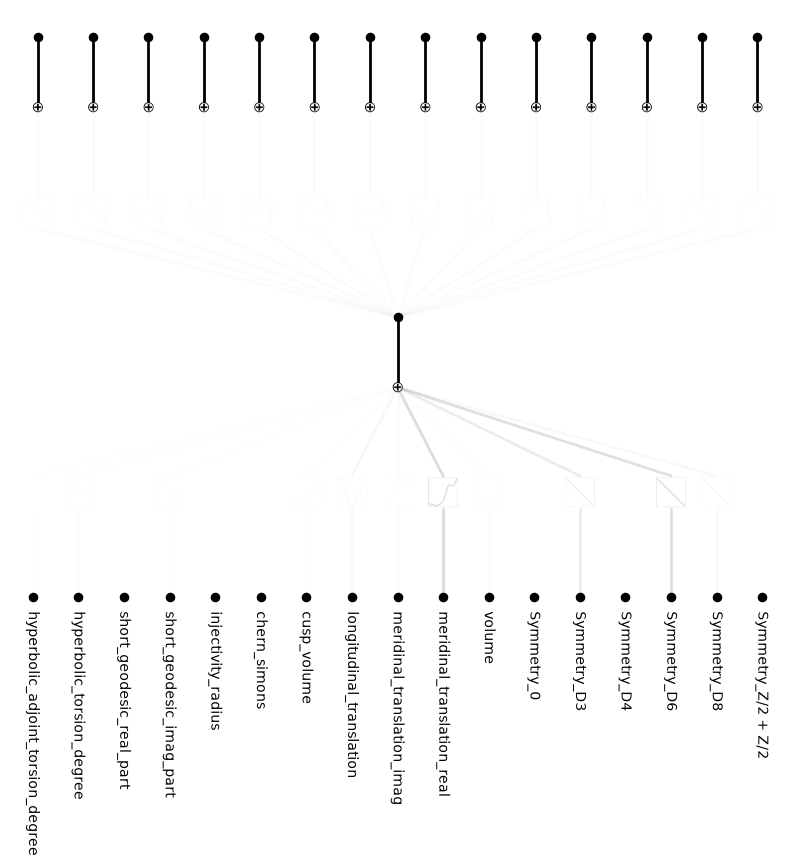

In [3]:
plot(model, train['x'], scale=1.0, beta=0.2)

n = 17
for i in range(n):
    plt.gcf().get_axes()[0].text(1/(2*n)+i/n-0.005,-0.02,df.keys()[1:-1][i], rotation=270, rotation_mode="anchor")

Text(0, 0.5, 'feature importance')

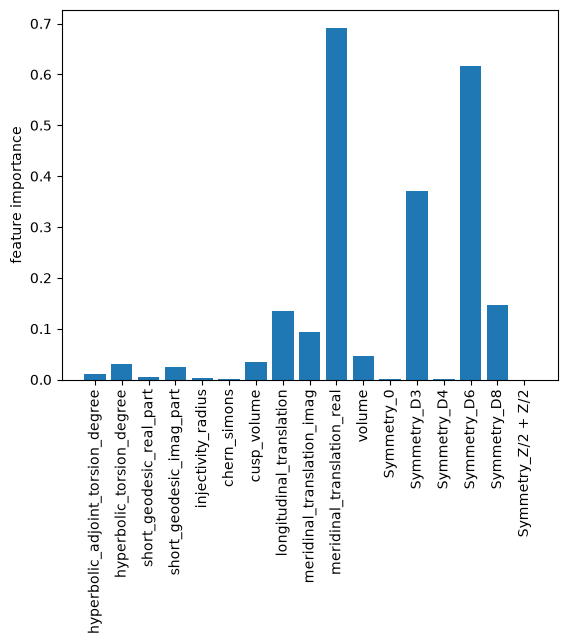

In [4]:
scores = feature_score(model, train['x']).cpu().numpy()
features = list(df.keys()[1:-1])

y_pos = range(len(features))
plt.bar(y_pos, scores)
plt.xticks(y_pos, features, rotation=90);
plt.ylabel('feature importance')